> **Recommended: run this notebook in Google Colab, nothing to install.**
>
> [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/workshop/03-how-a-navigate-model-is-built.ipynb)
>
> Just click on the "Open in Colab" button and follow along. Click the ▶ button on each cell (or press Shift+Enter) to see the results and move on to the next one.
>
> If you can't or don't want to use Colab, the documentation website shows the pre-run results.

# Session 3: How a Navigate model is built

The aim of this section is to cover the basics of Navigate's logic using the example from [Session 1](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/workshop/01-run-a-simple-case.ipynb) as an illustration.

This session shows how the deck is built and the data behind it. [Session 4](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/workshop/04-how-navigate-solves.ipynb) shows how the model solves it step by step, and its results in detail.


![Map of the Chile to Rotterdam copper trade: the two bunker ports, a fleet of ships on the voyage via the Panama Canal, and the fuel production sites in Patagonia and southern Sweden, both of which make e-methanol and e-ammonia, with bio-methanol in Sweden as well](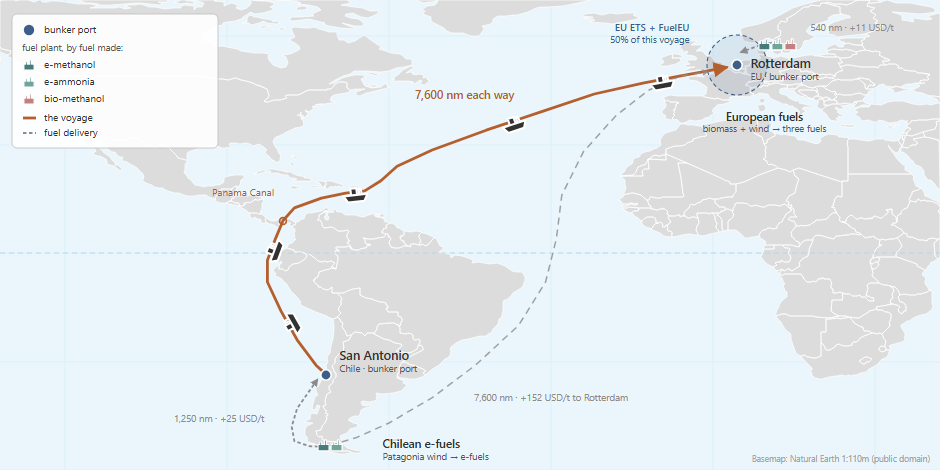)

*San Antonio to Rotterdam via the Panama Canal: the two bunker ports, the
voyage, and the possible fuel plants.*

## What you'll do

**Part 1: Build the deck.** See how a case like this is expressed using Navigate's components library.

**Part 2: Explore the input data.** Look at the numerical assumptions that will drive the answer.

[Session 4](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/workshop/04-how-navigate-solves.ipynb) then follows the model as it solves this case, step by step, and shows how much the owners' behaviour matters.


## Setup

Run the cell below on Colab or locally to set up the Navigate model. It also loads the pre-made example that will be used to illustrate this part of the workshop.

In [1]:
# @title Setup
# Setup. Works both on Google Colab and in a local checkout of the repository.
import os
from pathlib import Path


# The branch these notebooks live on, and the one Colab clones. The "Open in
# Colab" badge at the top of the notebook, like the links between the
# notebooks, opens the copy on the workshop-colab branch instead: the same
# notebooks with their outputs cleared, rebuilt from this branch by
# .github/workflows/workshop-colab.yml. Change BRANCH, and that workflow, to
# "main" once the branch has been merged.
BRANCH = "dev-workshop"


def at_repo_root() -> bool:
    """True if the working directory is the root of the repository."""
    return Path("navigate").is_dir() and Path("assumptions").is_dir()


if at_repo_root():
    print("Already at the repository root.")
elif Path("../../navigate").is_dir():
    # Local Jupyter starts the kernel in the notebook's own folder,
    # docs/workshop/, but the paths below are relative to the repository root.
    os.chdir("../..")
    print("Moved up to the repository root.")
else:
    # Colab, or any other fresh environment
    if not Path("navigate-zcs").is_dir():
        !git clone --depth 1 -b {BRANCH} https://github.com/zerocarbonshipping/navigate-zcs.git
    os.chdir("navigate-zcs")
    print("Cloned the repository and moved into it.")

assert at_repo_root(), f"not at the repository root: {Path.cwd()}"

# `import navigate` is not a usable test here: from the repository root it
# succeeds because the source folder is present, which leaves the `navigate`
# command itself missing.
import sys
from importlib.metadata import PackageNotFoundError, version

try:
    print(f"Navigate {version('navigate-zcs')} is already installed.")
except PackageNotFoundError:
    %pip install -q .
    print("Installed Navigate.")


# Load the example deck.
EXAMPLE = Path("simulations/examples/example_4")

# Fail loudly rather than printing an empty list. The setup above clones the
# branch named in BRANCH, so this deck is only here once it has been committed
# and pushed to that branch.
assert EXAMPLE.is_dir(), (
    f"{EXAMPLE} not found under {Path.cwd()}. On Colab the setup cell clones the "
    f"{BRANCH!r} branch, so this deck has to be committed and pushed there "
    "before the notebook can read it."
)


def show(path, first=None, grep=None, code_only=False):
    """Print a deck file: all of it, the first N lines, matching lines, or the
    command lines only (`code_only`, which drops the comments)."""
    lines = Path(path).read_text(encoding="utf-8").splitlines()
    if code_only:
        print(f"# {Path(path).name}: command lines only, "
              f"open the file for the commentary")
        lines = [ln for ln in lines if ln.strip() and not ln.strip().startswith("#")]
    if grep:
        lines = [ln for ln in lines if grep in ln]
    if first:
        lines = lines[:first]
    for ln in lines:
        print(ln)


deck = sorted(EXAMPLE.rglob("*.nav")) + sorted(EXAMPLE.rglob("*.inc"))
assert deck, f"no .nav or .inc files under {EXAMPLE.resolve()}"

Moved up to the repository root.
Navigate 1.0.0 is already installed.


---

## Part 1: Build the deck

Navigate is a bit like a "drag and drop" model: you pick some components (*nodes*) from the ones available and add them to your simulation (*deck*).

A **deck** is the input to a Navigate run: one `.nav` file plus the `.inc` files it includes. Navigate is the program, and the deck is the instructions you hand it. A **node** is one declared thing, written as a type, a name in quotes, and a block of attributes.

The `.nav` file is just a table of contents with two sections —
`DEFINE` for the nodes the simulation is made of, and `EVENTS` for the timeline
it steps through.

`Include` adds one of the deck's files, by its path. `Load` adds a ready-made module from the Center's assumptions library, by its name.

Check the [Reference Manual](https://zerocarbonshipping.github.io/navigate-zcs/reference_manual/index.html) and follow the [Tutorials](https://zerocarbonshipping.github.io/navigate-zcs/tutorials/index.html) if you want more details on this.

Read the `.nav` file first, to see how the deck is built for the current case.

In [2]:
show(EXAMPLE / "example_4.nav")

# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# EXAMPLE 4 - Panamax fleet, Chile to Rotterdam.

DEFINE {
    Load DefaultModelDefinition

    # ---- fleet ----
    Include "includes/fleet.inc"
    Include "includes/energy_efficiencies.inc"

    # ---- route ----
    Include "includes/route.inc"
    Include "includes/ports.inc"
    Include "includes/bunker_logistics.inc"

    # ---- fuel ----
    Include "includes/fuel_production.inc"
    Include "includes/regions.inc"
    Include "includes/producer.inc"
    Load DefaultEmission

    # ---- regulation ----
    Include "includes/eu_ets.inc"
    Include "includes/fuel_eu.inc"

    # ---- decision processes ----
    Load DefaultCalibration

    # ---- export ----
    Include "includes/report.inc"

    Load DefaultPlot
}

EVENTS {
    Load DefaultTimeStepYearly
}


### Fleet definition

In our case, the fleet starts as 300 fuel-oil vessels set with `InitialVessels` and `InitialSplit`. 
`InitialAgeDistribution` is the age spread of the world's 80k DWT bulk carriers, taken from the library as `Curve("age_dist_bulk_carrier_80k_dwt_oil")`. Navigate splits the fleet into one cohort per year of age, and the retrofit decision will be taken **per cohort**.

Two mechanisms will compete over the next 25 years:

- **Retrofit** — convert an existing oil ship to methanol or ammonia. An LNG ship can only be bought new, and can itself be retrofitted to ammonia. The `set_fuel_conversion_cost` lines
put a price on retrofitting an existing oil ship to another configuration.
- **Replace** — do nothing until a cohort retires, then let all four
  configurations compete as newbuilds.

Run the next cell to look in more detail at how the "fleet" is implemented in Navigate.

In [3]:
show(EXAMPLE / "includes/fleet.inc")

# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# FLEET - Panamax bulk carriers (~80,000 DWT), four configurations of one hull.
# All four share hull, propulsion curve, cargo capacity and OPEX.

Copy Vessel "bulk_carrier_80k_dwt_ice_oil"      "ship_oil"
Copy Vessel "bulk_carrier_80k_dwt_ice_methane"  "ship_lng"
Copy Vessel "bulk_carrier_80k_dwt_ice_methanol" "ship_methanol"
Copy Vessel "bulk_carrier_80k_dwt_ice_ammonia"  "ship_ammonia"

Fleet "copper_trade" {
	Vessels = [Vessel("ship_oil"),
	           Vessel("ship_lng"),
	           Vessel("ship_methanol"),
	           Vessel("ship_ammonia")]

	InitialVessels = 300 # Arbitrary number (represents 8% of the world Panamax fleet)
	InitialSplit = [1.0, 0.0, 0.0, 0.0] # Only ship oil vessels

	InitialAgeDistribution = [
		Curve("age_dist_bulk_carrier_80k_dwt_oil"),
		0,
		0,
		0
	]
	# Note: Orderbooks omitted for this example since the library's are sized for

#### What a `Vessel` node looks like

`fleet.inc` never describes the ships themselves. It reaches for them with
`Copy Vessel`, which takes a vessel out of our assumptions library and gives
the copy a local name — so `ship_lng` is a copy of
`bulk_carrier_80k_dwt_ice_methane`.

Run the next cell to check what goes into a vessel node. It shows the dual-fuel
LNG ship, with the power system it names and the two engines in it:

- the vessel has two tanks: one for LNG, and one for the oil its engines need as
  pilot fuel
- its power system has three converters: the main engine (propulsion), the
  generators (electricity) and a boiler (heat, which burns oil)
- both engines are dual-fuel: they run on LNG (`MainFuelTypes = METHANE`), but at
  least 1.5 % of their energy must come from oil (`MinimumPilotFuel`), and they
  can burn more oil whenever that is cheaper
- each engine lets some methane escape unburned (`set_slip_fraction`): 0.175 % in
  the main engine but 11.4 % in the generators, so the generators get less energy
  out of each ton of LNG

In [4]:
# fleet.inc reaches four vessels with `Copy Vessel`. Here is the dual-fuel LNG one,
# then the power system it names and the two dual-fuel engines in that.
LIBRARY = Path("assumptions/defaults/installation")
show(LIBRARY / "Vessel" / "bulk_carrier_80k_dwt_ice_methane.inc")
show(LIBRARY / "PowerSystem" / "ice_methane_bulk_carrier_80k_dwt.inc")
show(LIBRARY / "Converter" / "propulsion_ice_methane_bulk_carrier_80k_dwt.inc")
show(LIBRARY / "Converter" / "electrical_ice_methane_bulk_carrier_80k_dwt.inc")

# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

Vessel "bulk_carrier_80k_dwt_ice_methane" {
	
	PropulsionLoad = Surface("bulk_carrier_80k_dwt_propulsion_load")
	ElectricalLoadAtSea = Variable("bulk_carrier_80k_dwt_electrical_load_sea")
	ElectricalLoadInPort = Variable("bulk_carrier_80k_dwt_electrical_load_port")
	HeatLoadAtSea = Variable("bulk_carrier_80k_dwt_heat_load_sea")
	HeatLoadInPort = Variable("bulk_carrier_80k_dwt_heat_load_port")
	
	PowerSystem = PowerSystem("ice_methane_bulk_carrier_80k_dwt")
	Tanks = [Tank("main_methane_bulk_carrier_80k_dwt"), Tank("pilot_oil_bulk_carrier_80k_dwt")]
	
	Route = Route("operational_profile_bulk_carrier_80k_dwt")
	NominalCapacity = Variable("bulk_carrier_80k_dwt_nominal_capacity")
	Lifetime = Variable("bulk_carrier_80k_dwt_lifetime")
	
	CAPEX = Forecast("bulk_carrier_80k_dwt_capex")
	OPEX = Forecast("bulk_carrier_80k_dwt_opex")
	CostOfCapital = Variable("cost_of_

### Route definition

In this example, the ships sail between the ports of San Antonio and Rotterdam, 7,600 nm apart via the Panama Canal (the route is invented), at a service speed of 11.5 kn and spend 6.8 days in each port.

The two legs (a leg is one one-way sailing from one port to the next) are asymmetric in this example. Outbound the ship is full of copper concentrate; homebound it sails in ballast (empty). In the model, this can be set as `CapacityUtilizations = [1.0, 0.0]`.

In [5]:
show(EXAMPLE / "includes/route.inc")

# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# ROUTE - San Antonio to Rotterdam and back via the Panama Canal.
# ROUND_TRIP visits the ports in the order listed; each entry in
# Distances/Speeds/CapacityUtilizations is the leg (the sailing
# to the next port) leaving the port at that index.

Vessel "ship_*" {
    Route = Route("copper_route")
}

Route "copper_route" {
    RouteType = ROUND_TRIP

    Ports = [Port("san_antonio"), Port("rotterdam")]

    # Days alongside per call, from the library's operational profile for this
    # class: TimeAtSea 0.55 over 24 calls/year = 0.45 x 365 / 24.
    PortDurations = [6.8, 6.8]

    # The distances for this example are invented since this route geography
    # is not included in the Navigate Assumption.
    Distances = [7600, 7600]

    # Modal service speed from the library's operational profile for this ship class.
    Speeds = [11.5, 11.5]

    # Laden ou

### Ports definition
In this example, we assume that both ports sell the same five fuels: fuel oil, LNG, e-ammonia, e-methanol and bio-methanol. Fuel is shipped from the region that made it to the port that needs it, at a given transport cost, a function of the distance it travelled.


In [6]:
show(EXAMPLE / "includes/ports.inc")

# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# PORTS - what can be bunkered where. All three alternative fuels are bunkerable at
# both ports; a fuel is shipped to the port that did not produce it, the same way
# Chilean e-ammonia reaches Rotterdam.
# Delivered price is production cost plus transport, set in bunker_logistics.inc.

Port "san_antonio" {
    set_bunkering_allowed("methanol_electro", TRUE)
    set_bunkering_allowed("ammonia_electro", TRUE)
    set_bunkering_allowed("methanol_bio", TRUE)
}

Port "rotterdam" {
    set_bunkering_allowed("methanol_electro", TRUE)
    set_bunkering_allowed("ammonia_electro", TRUE)
    set_bunkering_allowed("methanol_bio", TRUE)
}

Port "*" {
    # the two fossil fuels are treated as globally traded and available anywhere
    set_bunkering_allowed("fossil_fuel_oil", TRUE)
    set_bunkering_allowed("liquefied_natural_gas", TRUE)

    # Fossil prices and upstream

### Fuel production

Five fuels are considered in this model: oil, LNG, e-ammonia, e-methanol and bio-methanol.
A vessel is defined by the fuel **type** its engine and tanks accept, and several fuels can satisfy one type. For example, the same methanol ship can accept bio-methanol, e-methanol or oil (dual-fuel engine).

E-ammonia, e-methanol and bio-methanol need to be produced by a fuel plant. 

In [7]:
show(EXAMPLE / "includes/fuel_production.inc")

# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# FUEL PRODUCTION - five fuels for four ships; both methanols feed one ship.
#
# Only the siting and financing are set here (region, electricity source and
# cost of capital, which Import Plant does not bring: the library sets it in
# DefaultPlant). Lead times, lifetimes, capacities and process economics come
# from the library.
# Feedstock ceilings for the two methanols are set in producer.inc.

# ---- fossil (global commodities, no production chain modelled) --------------
Import Fuel "fossil_fuel_oil"
Import Fuel "liquefied_natural_gas"

# ---- Chilean e-methanol -----------------------------------------------------
Import Fuel "methanol_electro"
Import Plant "plant_methanol_electro_alkaline"
Plant "plant_methanol_electro_alkaline" {
    Region = Region("americas")
    Source = Source("renewable")   # dedicated wind, not the Chilean grid
    CostOfCapita

A **producer** is the agent that decides whether to build fuel plants or not and which ones. 

We have two producers in this model: an e-fuel producer that can build e-ammonia and e-methanol in either Patagonia or Europe, and a biofuel producer that builds bio-methanol (only in Europe).

The feedstocks for bio-methanol (biomass) and e-methanol (biogenic CO2) are constrained (using an arbitrary number in this simulation), meaning that plant build is limited for these two fuels. 

In the model it is also possible to constrain the number of fuel plants that can be built in a year (but it will not be binding for our example).

In [8]:

show(EXAMPLE / "includes/producer.inc")

# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# PRODUCERS - the agents that decide whether to build another plant.

Producer "producer_efuel" {
	Plants = [Plant("plant_methanol_electro_alkaline"),
	          Plant("plant_ammonia_electro_alkaline"),
	          Plant("plant_methanol_electro_alkaline_europe"),
	          Plant("plant_ammonia_electro_alkaline_europe")]

	MaximumDevelopment = <Forecast("epc_global_capacity_mid") * Forecast("epc_global_share_shipping")>

	# Ceiling on biogenic CO2, the feedstock both its e-methanol plants draw on.

	set_feed_constraint("carbon_dioxide_biogenic", <Forecast("carbon_dioxide_biogenic_availability_flat") * Forecast("carbon_dioxide_biogenic_share_shipping") * Variable("trade_share_biogenic_carbon_dioxide")>)
}

Producer "producer_biofuel" {
	Plants = [Plant("plant_methanol_bio_gasification")]

	MaximumDevelopment = <Forecast("epc_global_capacity_mid") * Forecast("

### Implement bunker logistics

`LiquidMarketFuels` such as fuel oil and LNG are treated as global commodities:
available anywhere at a quoted price, with no plant, producer or logistics chain
modelled.

Everything else has to be physically moved from the plant to the bunker port,
priced at `distance × rate`. `set_distance` gives the sea distance from a
production region to a port, and `set_transport_cost` the rate per ton per
nautical mile.

At the port, `set_handling_cost` (in the ports file above) adds a fixed cost per ton
for storage and the bunkering service. These per-ton charges are the only
infrastructure costs in Navigate: terminals, storage tanks and bunker vessels have
no investment cost and are never built. A slow or costly port build-out has to be
entered by hand: `set_bunkering_allowed` or `set_bunkering_limit` for when and how
much a port can deliver, and a higher or time-varying handling cost for what it costs.

In [9]:
show(EXAMPLE / "includes/bunker_logistics.inc")

# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# BUNKER LOGISTICS - production site to bunker port.
# LiquidMarketFuels are treated as global commodities: quoted price, no plant,
# no producer, no logistics chain. Everything else picks up distance x rate.

BunkerLogistics {
	LiquidMarketFuels = [Fuel("fossil_fuel_oil"), Fuel("liquefied_natural_gas")]

	# The values have been invented for this example:
	# nautical miles from the production region to each port
	set_distance("americas", "san_antonio", 1250)
	set_distance("americas", "rotterdam", 7600)
	set_distance("europe", "rotterdam", 540)
	set_distance("europe", "san_antonio", 7600)

	# USD per ton per nautical mile
	set_transport_cost("*", 0.02)
}


### Implement regulations (FuelEU and EU ETS)

![The EU regulatory package: the Renewable Energy Directive sets emissions values, sustainability criteria, GHG emission savings and certification; FuelEU Maritime limits the GHG intensity of fuel on a declining staircase to 2050, with penalties paid for emissions above the annual target and pooling rewarding vessels below it; and the EU Emissions Trading System puts a price on every tonne of GHGs, with ships buying EU Allowances](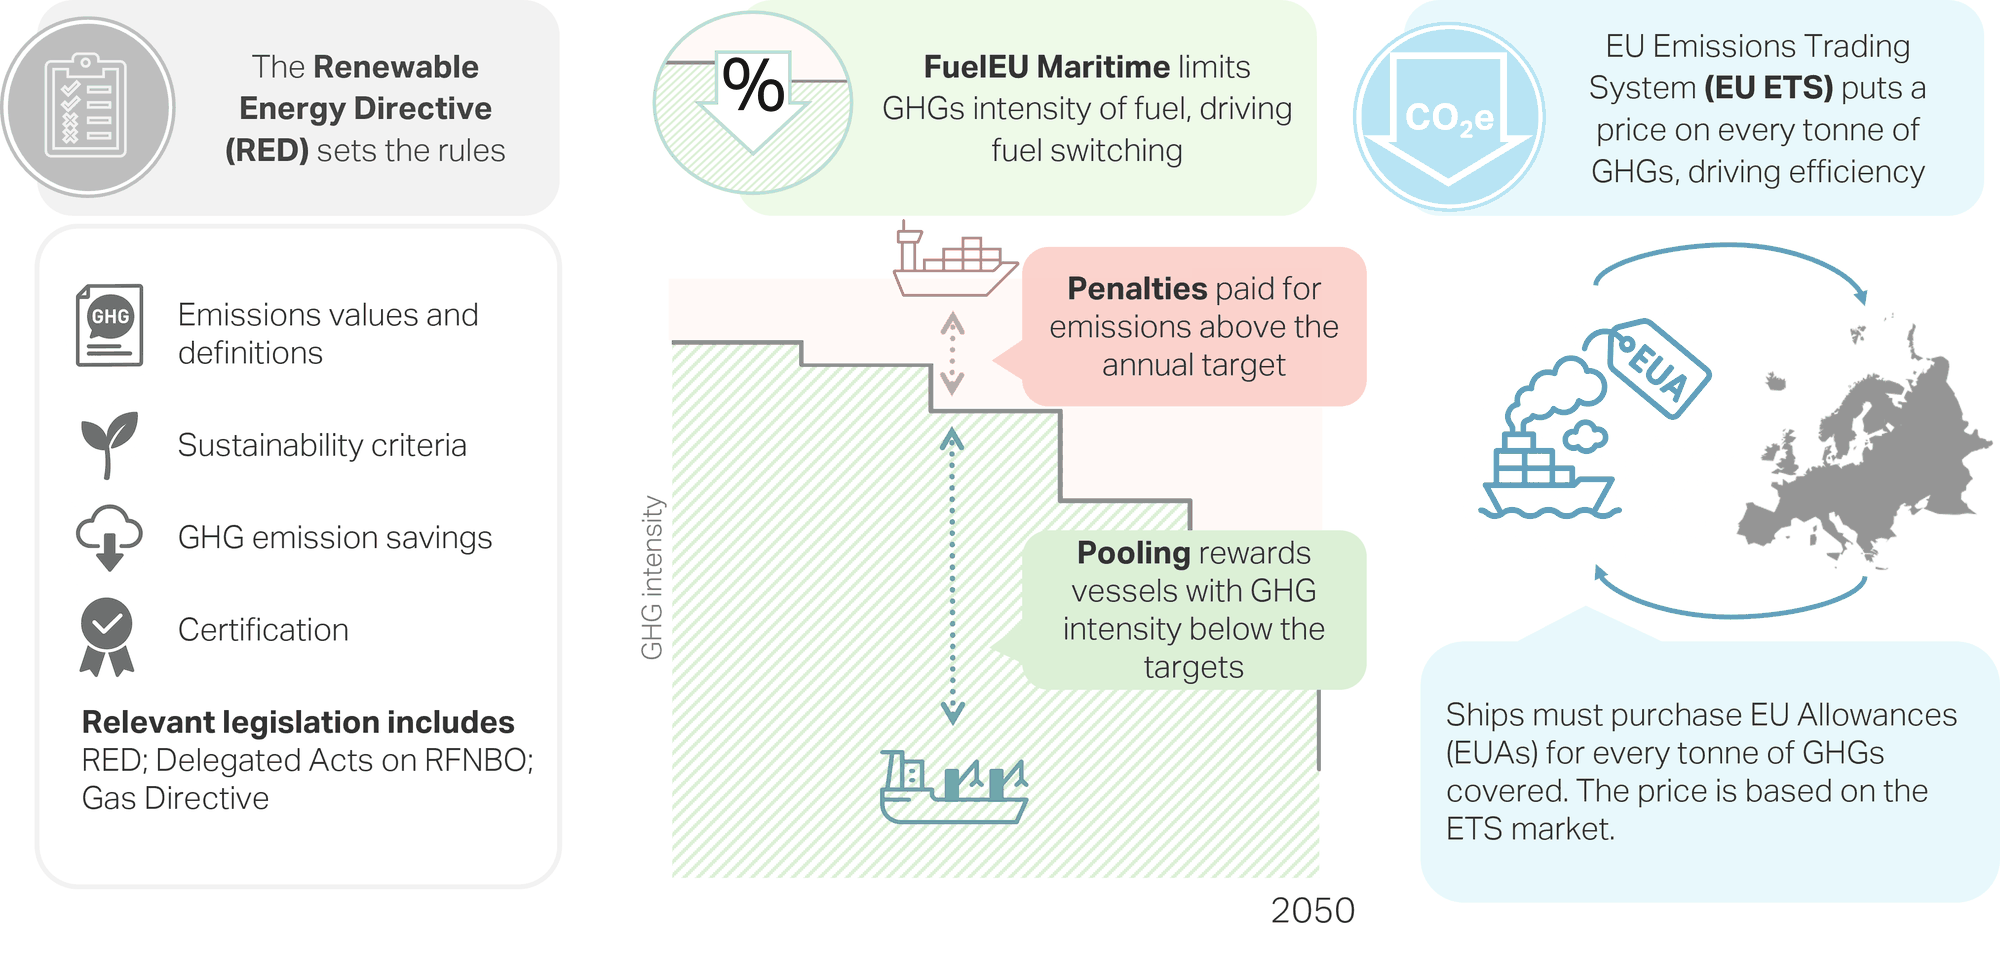)

*FuelEU Maritime caps the GHG **intensity** of the fuel and so drives fuel switching; the EU ETS prices **every tonne** emitted and so drives efficiency. The Renewable Energy Directive supplies the definitions and certification both rely on.*

In Navigate a regulation is applied to a specific geography. `Jurisdiction` lists the
ports that sit inside the regulatory scheme. In this example, FuelEU and EU ETS cover the port of Rotterdam, but not San Antonio. Three fractions decide how much of the fuel burned on a voyage is counted.

The fractions are applied leg by leg (a *leg* is one port-to-port sailing between
two consecutive ports on the route). This round trip has two, out and back. Navigate reserves the word for the ship's own
route segments, so a fuel's journey from plant to bunker port is a *trip*, not a
leg (a sailing of the ship itself). Navigate classifies each leg (sailing out or back) by its two end ports, and each port stay by its port. On this round trip that gives:

| Leg (one-way sailing) or port stay | Classification | Counted for regulation |
|---|---|---|
| San Antonio → Rotterdam, 7,600 nm ≈ 27.5 days | one end inside → `InterFraction` | **50 %** |
| Rotterdam → San Antonio, 7,600 nm ≈ 27.5 days | one end inside → `InterFraction` | **50 %** |
| alongside in Rotterdam, 6.8 days per call | inside → `IntraFraction` | **100 %** |
| alongside in San Antonio, 6.8 days per call | outside → `ExtraFraction` | 0 % |

The two instruments apply to different emission scopes:

- EU ETS on **TTW — tank to wake.** Emissions that come out of the ship engine.
- FuelEU on **WTW — well to wake.** TTW, plus emissions to make and deliver the
  fuel.

Each instrument is one `Regulation` node, and the `.nav` includes one file per
instrument — `includes/eu_ets.inc` and `includes/fuel_eu.inc`.

Beyond the geography, most of the content is **emission factors**: a
`set_fuel_ttw` line per fuel per gas, saying what a ton of that fuel emits once
burned. FuelEU adds `set_fuel_wtt` lines for the fuels whose upstream value the
regulation fixes by default.
E-fuels are omitted since there are no default factors. Upstream intensity is then calculated by Navigate from the production chain in `regions.inc`.

In [10]:
show(EXAMPLE / "includes/eu_ets.inc")

# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# EU ETS - absolute price on CO2-equivalent burned on board, no free allowance.
#
# The coverage fractions are applied PER LEG (one sailing
# from one port to the next), not to the round trip. Both legs
# here are inter-jurisdiction, so both count at 50%. Port stays are classified
# by their own port, so Rotterdam counts in full and San Antonio not at all.

Regulation "eu_ets" {
	Measure = ABSOLUTE
	Scheme = INDIVIDUAL
	Scope = TTW
	IncludeSlip = FALSE   # methane slip is carried in the TTW methane factors
	Emissions = [Emission("carbon_dioxide"), Emission("methane"), Emission("nitrous_oxide")]
	Fuels = Fuel("*")

	# Rotterdam is the only EU port on this route
	Jurisdiction = [Port("rotterdam")]
	IntraFraction = 1     # both ends in the EU
	InterFraction = 0.5   # one end in the EU
	ExtraFraction = 0     # neither end in the EU

	RemedialCost = <Forecast("e

FuelEU is the same shape, with two differences to look for: `Scheme = FLEXIBLE` (applies for the fleet) instead of `INDIVIDUAL` (applies per vessel), and the `set_fuel_wtt` lines that fix upstream intensity for the fossil fuels and bio-methanol — but not for the two e-fuels.

In [11]:
show(EXAMPLE / "includes/fuel_eu.inc")

# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# FUELEU MARITIME - caps WTW greenhouse gas intensity, tightening over time.
#
# The e-fuels get no default set_fuel_wtt. Instead, Navigate calculates
# their upstream intensity from the production chain in regions.inc, so the
# power price at each site feeds their FuelEU score. The fossil fuels and
# bio-methanol instead use the regulation's own defaults.
#
# Same coverage geography as eu_ets.inc.

Regulation "fuel_eu" {
	Measure = INTENSITY
	Scheme = FLEXIBLE     # pooled and banked across years, unlike the ETS
	Scope = WTW
	IncludeSlip = FALSE   # methane slip is carried in the TTW methane factors
	Emissions = [Emission("carbon_dioxide"), Emission("methane"), Emission("nitrous_oxide")]
	Fuels = Fuel("*")

	Jurisdiction = [Port("rotterdam")]
	IntraFraction = 1
	InterFraction = 0.5
	ExtraFraction = 0

	RemedialCost = Variable("fuel_eu_remedial_cost")

	Sha

#### In summary

| | FuelEU Maritime | EU ETS |
|---|---|---|
| What it limits | the **intensity** of the energy used, gCO2eq/MJ | the **quantity** emitted, tonnes CO2eq |
| What you pay | a penalty on how far you miss the annual target | a price on every covered tonne |
| Emissions counted | **well-to-wake**: how the fuel was made counts | **tank-to-wake**: only what the ship burns on board |

For FuelEU, the limit is a **staircase**: it holds flat for years and then
steps down, so the pressure to switch arrives in jumps rather than smoothly.


---

## Part 2: Explore the input data

Before running the model, let's look at the numbers behind it since they
explain most of the results.

Navigate fetches numerical assumptions from the assumptions library as it reads the deck.


### Numerical assumptions in Navigate

Almost every numerical assumption in Navigate is a **lookup table** written into a `.inc`
file: when the model needs a value it reads one out of the table. Five node types carry the numbers:

| Node | Looked up by | Example |
|---|---|---|
| `Variable` | nothing — it is a single number | `fuel_eu_remedial_cost`: **760 USD/ton CO2eq** of shortfall |
| `Curve` | one number | `age_dist_bulk_carrier_80k_dwt_oil`: at age 12, **10.6 %** of the fleet |
| `Forecast` | a date | `eu_ets_carbon_credit_price`: in 2050, **417 USD/ton CO2eq** |
| `Surface` | two numbers | `bulk_carrier_80k_dwt_propulsion_load`: at 11.5 kn and utilisation 1 (full), **4.82 MW** |
| `Timetable` | a date *and* a number | `methanol_synthesis_electro_capex`: in 2025, a 4,000 t/day plant costs **558 USD/(ton of annual capacity)** |

The Center has collected a wide range of these numbers from partners and external
sources, and they have been validated by experts. They can all be found in the
`assumptions` folder.

That folder holds two parts, `defaults/` and `modules/`, each with an `installation` and a `user` copy.
`defaults/` holds individual nodes, one folder per type, and is read whenever a deck names
one: `Import Fuel "methanol_bio"` picks up
`defaults/installation/Fuel/methanol_bio.inc`. 

`modules/` holds ready-made bundles invoked with `Load`: `Load DefaultRegulation` reads
`modules/installation/default_regulation.inc`, which is itself just a short list of
imports. 

In both cases Navigate looks in `user/` first and falls back to
`installation/`, so you can use your own numbers by dropping a file into the
matching `user/` folder under the same name. It then takes precedence over the
Center's values.

See the reference manual for
[Forecast](https://zerocarbonshipping.github.io/navigate-zcs/reference_manual/forecast.html),
[Curve](https://zerocarbonshipping.github.io/navigate-zcs/reference_manual/curve.html),
[Surface](https://zerocarbonshipping.github.io/navigate-zcs/reference_manual/surface.html),
[Timetable](https://zerocarbonshipping.github.io/navigate-zcs/reference_manual/timetable.html)
and
[Variable](https://zerocarbonshipping.github.io/navigate-zcs/reference_manual/variable.html)
if you want more details.


The next cell needs to be run to prepare the data extraction from Navigate.


In [12]:
# @title Parse the deck and solve it once
import argparse
import contextlib
import io
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from navigate.bunker.bunker_algorithm import BunkerAlgorithm
from navigate.core.enum_ import BunkerScopeID
from navigate.core.expectations.vessel_expectation import VesselExpectation
from navigate.fuel.producer import producer_planning
from navigate.vessel.fleet import fleet_technology
from navigate.manager import SimulationManager

# The Setup cell at the top normally moves us to the repository root. Repeat the
# check here so this Part also works on its own, e.g. after a kernel restart.
if not (Path("navigate").is_dir() and Path("assumptions").is_dir()):
    if Path("../../navigate").is_dir():
        os.chdir("../..")
assert Path("assumptions").is_dir(), (
    f"not at the repository root ({Path.cwd()}) -- run the Setup cell at the "
    "top of the notebook first"
)

# This version of Navigate's solver can hang on one year of a run. This caps the
# method that hangs and solves that year again with another one; runs that solve
# today are unchanged. See _solver.py.
_STYLE_DIR = str(Path("docs/workshop").resolve())
if _STYLE_DIR not in sys.path:
    sys.path.insert(0, _STYLE_DIR)
from _solver import guard_interior_point

guard_interior_point()

NAV = Path("simulations/examples/example_4/example_4.nav")
ARGS = argparse.Namespace(data_dir=Path("./assumptions"), solver=None)

# Parse the deck, then solve it once. Part 2 is mostly about inputs, but the
# fuels' well-to-tank emissions are not an input at all -- Navigate derives them
# from the production chain -- so the run is what makes them readable. Every later
# cell in this Part reads its numbers off `manager`; Session 4 builds its own.
manager = SimulationManager()
manager.read_deck(NAV, ARGS)

# Copy the Regulation's emission factors before the run, so the charts in this Part
# can show what the DECK states and never something the run derived. A factor the deck
# leaves out stays None here, which is exactly how the model reads it: supplied factors
# are used as given, omitted ones are derived from the fuel and the converter.
DECK_FACTORS = {name: {"gwp": dict(reg.global_warming_potential),
                       "ttw": dict(reg.fuel_TTW),
                       "wtt": dict(reg.fuel_WTT)}
                for name, reg in manager.nodes.regulations.items()}

with contextlib.redirect_stdout(io.StringIO()):   # one line per year, not needed here
    manager.run()

import matplotlib.pyplot as plt


def forecast_to_frame(name, nodes=None):
    """A Forecast node's resolved (date, value) table as a DataFrame."""
    node = (nodes or manager.nodes).forecasts[name]
    return pd.DataFrame({"date": pd.to_datetime(node.get_x_date()),
                         "value": [node.calculate(x) for x in node.get_x()]})


def forecast_curve(name, points=600):
    """What the model actually returns for a Forecast, sampled densely.

    Joining the table rows with straight lines would imply linear interpolation.
    `fuel_eu_target_reduction` sets `Interpolate = PREVIOUS`, so it holds each
    value flat and then steps down. Sampling calculate() draws whatever the node
    really does, whichever mode it uses.
    """
    node = manager.nodes.forecasts[name]
    xs = np.asarray(node.get_x(), dtype=float)
    rows = pd.to_datetime(node.get_x_date())
    grid = np.linspace(xs.min(), xs.max(), points)
    when = rows[0] + pd.to_timedelta(grid - xs[0], unit="D")
    return when, np.array([node.calculate(x) for x in grid])


# One house style for every figure in the workshop. It lives in
# docs/workshop/_style.py rather than in this cell, so that this notebook and
# notebook 2 cannot drift apart - which is exactly what had happened. The
# colours are Navigate's own, and that file explains the one thing about them
# that surprises people: the hue says how a fuel was MADE, not which molecule it
# is, so bio-methanol and e-methanol are deliberately different colours.
import sys

_STYLE_DIR = str(Path("docs/workshop").resolve())
if _STYLE_DIR not in sys.path:
    sys.path.insert(0, _STYLE_DIR)

from _style import (AXIS, BLUE, GREEN, GRID, INK, MUTED, ORANGE, PALE, SUBINK,
                    TICK, config_colour, config_label, cost_colour, fuel_colour,
                    fuel_label, fuel_sorted, series_colours)


def panel(ax, series, title, ylab):
    """One forecast panel: the model's own response, with its table rows marked."""
    for (name, label), colour in zip(series, (BLUE, ORANGE)):
        when, value = forecast_curve(name)
        ax.plot(when, value, color=colour, lw=2, label=label, zorder=3)
        rows = forecast_to_frame(name)
        if len(rows) <= 8:          # mark the rows only where they are readable
            ax.plot(rows["date"], rows["value"], "o", color=colour, ms=5,
                    mec="white", mew=1.2, zorder=4)
    ax.set_title(title, fontsize=10, color=INK, loc="left")
    ax.set_ylabel(ylab, fontsize=8, color=SUBINK)
    ax.grid(color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TICK, labelsize=8)
    ax.margins(y=0.15)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)
    if len(series) > 1:             # a legend only where there are two to tell apart
        ax.legend(fontsize=8, frameon=False, labelcolor=SUBINK)


——————————————————————————————————————————————————————————————————————————————————————————————————
            |    |    |                                  .oO
           )_)  )_)  )_)                             __/___                  _    _
          )___))___))___)\                     _____/______|              __|_|__|_|__
         )____)____)_____)\\           _______/_____\_______\_____      _|____________|__
       _____|____|____|____\\\__       \              < < <       |    |o o o o o o o o /
~~~~~~~\                   /~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
        ´´´´´´´´´´´´´´´´´´´              Navigate
——————————————————————————————————————————————————————————————————————————————————————————————————
        Navigate - an integrated assessment model for decarbonizing shipping
        Developed by Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
        Version 1.0.0 - for questions, contact navigate@zerocarbonshipping.com


---

### 1. Data about the fleet

The most important data that will affect how the fleet ends up being designed are:
- the ship retrofitting costs from one fuel to another
- the CAPEX of newbuild ships and their financing conditions
- the efficiency technology on offer, and what it costs
- the sensitivity of shipowners towards different market signals

Data that also influences the fleet design but is not presented in this example is the ship orderbook (the ships already ordered but not yet delivered). The composition of the initial fleet (shown in Session 4) and the efficiency technology already installed also influence the final fleet design.

#### Newbuild CAPEX, retrofitting costs and financing conditions
Running the next cell shows some of our assumptions on ship retrofitting costs, the CAPEX of newbuild ships and the cost of capital each configuration is financed at.

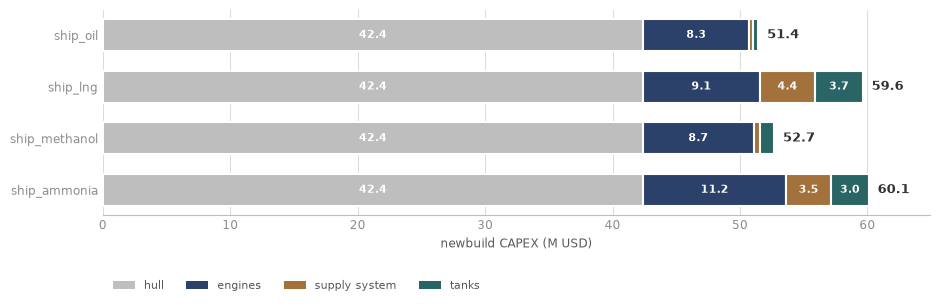

Retrofitting an existing ship, instead of replacing it:


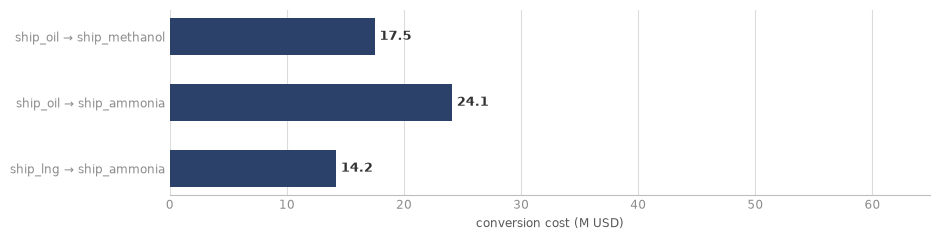

In [13]:
# @title Newbuild CAPEX, retrofit costs and cost of capital
# What the four configurations cost to build.
#
# In this example, the HULL is identical by design - same 80,000 DWT Panamax - so the premium
# for a dual-fuel ship is not in Vessel.CAPEX but in the machinery. The model charges three
# pieces of it, and the charter rate carries all three (navigate/vessel/charter.py):
#   engines        the converters in the PowerSystem, priced per MW installed
#   supply system  the PowerSystem's own CAPEX, a lump sum for fuel handling and safety
#   tanks          each Tank on the vessel, priced per m3 of containment
def scalar(x, t=0.):
    """Resolve a Forecast / Variable / plain number to a value at time t."""
    if hasattr(x, "calculate"):
        return float(x.calculate(t))
    if hasattr(x, "get"):
        return float(x.get())
    return float(x)

rows = []
for name, v in manager.nodes.vessels.items():
    engines = sum(scalar(c.power_capacity) * scalar(c.CAPEX)
                  for c in v.power_system.get_converters())
    supply = scalar(v.power_system.CAPEX)
    tanks = sum(scalar(t.size) * scalar(t.CAPEX) for t in v.tanks)
    machinery = engines + supply + tanks
    hull = scalar(v.CAPEX)
    rows.append({"configuration": name,
                 "hull (M USD)": hull / 1e6,
                 "engines (M USD)": engines / 1e6,
                 "supply system (M USD)": supply / 1e6,
                 "tanks (M USD)": tanks / 1e6,
                 "newbuild total (M USD)": (hull + machinery) / 1e6,
                 "capacity (DWT)": scalar(v.nominal_capacity),
                 "life (yr)": scalar(v.lifetime)})

table = pd.DataFrame(rows).set_index("configuration")
# The same four numbers as a picture, so the split is visible rather than read.
# The hull is drawn in grey because it is the part that does NOT vary: identical
# by design across all four, and still four fifths of the bill. Only the three
# machinery components carry a colour, because they are what the fuel choice moves.
from matplotlib.patches import Patch

COMPONENTS = [("hull (M USD)", "hull", MUTED),
              ("engines (M USD)", "engines", BLUE),
              ("supply system (M USD)", "supply system", ORANGE),
              ("tanks (M USD)", "tanks", GREEN)]

fig, ax = plt.subplots(figsize=(9.5, 3.4))
y = range(len(table))
left = [0.] * len(table)

for column, _label, colour in COMPONENTS:
    values = table[column].to_numpy()
    ax.barh(list(y), values, left=left, height=.62, color=colour, zorder=3,
            edgecolor="white", linewidth=1.5)
    for i, (value, start) in enumerate(zip(values, left)):
        if value >= 2.:                  # only where the segment can hold a number
            ax.annotate(f"{value:.1f}", (start + value / 2, i), ha="center",
                        va="center", fontsize=8, color="white", fontweight="bold",
                        zorder=5)
    left = [a + b for a, b in zip(left, values)]

for i, total in enumerate(left):
    ax.annotate(f"{total:.1f}", (total + 0.7, i), va="center", fontsize=9,
                color=INK, fontweight="bold")

ax.set_yticks(list(y), list(table.index))
ax.set_xlabel("newbuild CAPEX (M USD)", fontsize=8.5, color=SUBINK)
CAPEX_XLIM = max(left) * 1.08   # shared with the retrofit chart, so the two compare
ax.set_xlim(0, CAPEX_XLIM)
ax.invert_yaxis()
ax.grid(axis="x", color=GRID, lw=.8)
ax.set_axisbelow(True)
ax.tick_params(colors=TICK, labelsize=8.5, length=0)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(AXIS)
ax.legend(handles=[Patch(facecolor=colour, label=label)
                   for _column, label, colour in COMPONENTS],
          fontsize=8, frameon=False, labelcolor=SUBINK, ncol=4,
          loc="lower left", bbox_to_anchor=(0, -.42))
fig.tight_layout()
plt.show()

# What it costs to convert a ship that already exists, instead of replacing it.
# get_fuel_conversion_cost_pairs() returns only the pairs that were actually given
# a cost; the underlying dict also carries None-valued self-pairs.
fleet = manager.nodes.fleets["copper_trade"]
retrofits = pd.DataFrame(
    [{"from": frm, "to": to,
      "retrofit (M USD)": scalar(fleet.fuel_conversion_cost[(frm, to)]) / 1e6}
     for frm, to in fleet.get_fuel_conversion_cost_pairs()]
).set_index(["from", "to"])

print("Retrofitting an existing ship, instead of replacing it:")

fig, ax = plt.subplots(figsize=(9.5, 2.5))
routes = [f"{frm} \u2192 {to}"
          for frm, to in retrofits.index]
costs = retrofits["retrofit (M USD)"].to_numpy()

ax.barh(range(len(routes)), costs, height=.55, color=BLUE, zorder=3)
for i, cost in enumerate(costs):
    ax.annotate(f"{cost:.1f}", (cost + 0.4, i), va="center", fontsize=9,
                color=INK, fontweight="bold")

ax.set_yticks(range(len(routes)), routes)
ax.set_xlabel("conversion cost (M USD)", fontsize=8.5, color=SUBINK)
ax.set_xlim(0, CAPEX_XLIM)     # same scale as the newbuild chart above
ax.invert_yaxis()
ax.grid(axis="x", color=GRID, lw=.8)
ax.set_axisbelow(True)
ax.tick_params(colors=TICK, labelsize=8.5, length=0)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(AXIS)
fig.tight_layout()
plt.show()


The newbuild hull is the same 42.4 M USD whichever fuel it burns, so the newbuild premium
for going dual-fuel is entirely in the machinery (engines, supply system and tanks): about **+1.2 M for methanol,
+8.2 M for LNG, +8.7 M for ammonia** over a plain oil ship. Ammonia and LNG machinery cost
about the same, because both need containment and fuel-handling equipment that the oil ship
does not. For LNG almost all of the premium is that equipment; ammonia adds a dearer engine on top of it.

The loss of cargo is deliberately not included in the base assumptions: with an optimised ship design it can be reduced to a negligible amount.
(If needed, a number can however be added in the model by changing the Nominal Capacity of a specific ship.)

Important note: the ammonia ship is financed at an **11.05 %** rate in the near future (due to a higher risk) against **8.89 %** for the other
three, easing back to the same 8.89 % by 2030 (when the technology is expected to have matured).

#### Efficiency technology on offer, and what is already fitted

The assumptions library carries seven efficiency measures for this vessel
class. This deck fits all seven, each with its own cost and saving:

| Measure | Saves | CAPEX | OPEX/yr | Life |
|---|---|---|---|---|
| Exhaust-gas boiler (aux) | 5.0 % of heat | 100 k | 10 k | 25 yr\* |
| Lighting system | 2.5 % of electrical | 100 k | 0 | 25 yr\* |
| Variable frequency drive | 10.0 % of electrical | 100 k | 5 k | 25 yr\* |
| Propeller improvement devices | 2.0 % of propulsion | 150 k | 0 | 25 yr\* |
| Hull painting | 5.0 % of propulsion | 200 k | 24 k | **5 yr**, then repainted |
| Air lubrication | 4.0 % of propulsion | 1.5 M | 20 k | 25 yr |
| Flettner rotor | 0.4 MW of external power | 2.0 M | 40 k | 25 yr\* |

\* No lifetime is actually set, so the measure is never replaced: it stays on the ship until the ship leaves the fleet (at most 25 years, the library's lifetime for this class).

The efficiency measures are fitted following an efficiency technology *ladder*, meaning that the cheaper technologies are installed first.

Efficiency technologies are fitted on newbuild ships or during a retrofitting cycle that occurs every 5 years.

The fleet starts with a share of each technology already fitted, set by `set_initial_technology_share` in `includes/energy_efficiencies.inc` from the world Panamax fleet's shares in:

```
assumptions/defaults/installation/Curve/uptake_<measure>_bulk_carrier_panamax.inc
```

The Flettner rotor and air lubrication have no such curve, so they start at zero.

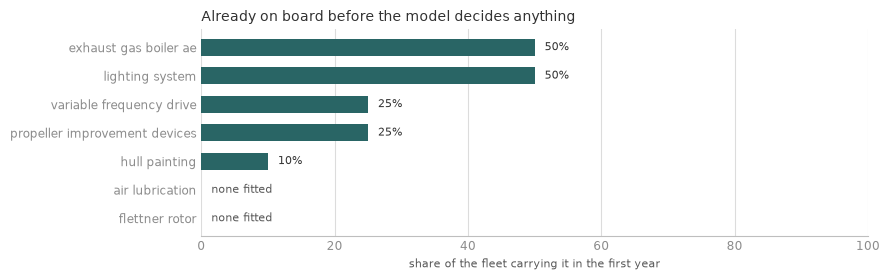

In [14]:
# @title Efficiency technology on offer, and what is already fitted
# What each hull already carries before the model decides anything. Read off the
# parsed deck: initial_technology_share maps (vessel, technology) to the library
# Curve the deck pointed it at, or None for a measure with no observed uptake.
_fleet_node = manager.nodes.fleets["copper_trade"]
start_share = {}
for (_vessel, _tech), _curve in _fleet_node.initial_technology_share.items():
    _short = _tech.replace("_bulk_carrier_panamax", "")
    start_share[_short] = float(_curve.get(0.)) if _curve is not None else 0.

# in the model's ladder order, cheapest first, as everywhere in the workshop
_order = [t.get_name().replace("_bulk_carrier_panamax", "")
          for t in _fleet_node.technology_packages[-1].technologies]

fig, ax = plt.subplots(figsize=(9, 2.9))
ax.barh(range(len(_order)), [start_share[t] * 100 for t in _order], height=.6,
        color=[GREEN if start_share[t] > 0 else MUTED for t in _order], zorder=3)
for _i, _t in enumerate(_order):
    ax.annotate(f"{start_share[_t] * 100:.0f}%" if start_share[_t] else "none fitted",
                (start_share[_t] * 100 + 1.5, _i), va="center", fontsize=8,
                color=INK if start_share[_t] else SUBINK)
ax.set_yticks(range(len(_order)), [t.replace("_", " ") for t in _order])
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("share of the fleet carrying it in the first year", fontsize=8,
              color=SUBINK)
ax.set_title("Already on board before the model decides anything", fontsize=10,
             color=INK, loc="left")
ax.grid(axis="x", color=GRID, lw=.8)
ax.set_axisbelow(True)
ax.tick_params(colors=TICK, labelsize=8.5, length=0)
for _side in ("top", "right", "left"):
    ax.spines[_side].set_visible(False)
ax.spines["bottom"].set_color(AXIS)
fig.tight_layout()
plt.show()


#### How sharply the owners react

The **decision sensitivities** defined in `Load DefaultCalibration`
set how sharply the owners respond to a cost difference.

`DefaultCalibration` also sets three **inertias**, which slow every decision down.
Each year, 60 % of the newbuilds follow the same mix of ship types as the year
before (`Inertia` on the `Fleet`), the producers do the same with their plants
(`Inertia` on the `Producer`), and every port keeps bunkering at least 70 % of what
it sold of each fuel the year before (`set_bunkering_inertia`).

In [15]:
# @title The decision sensitivities in this deck
# The sensitivities that govern how strongly an advantage translates into a
# change of fuel, of hull, or of equipment. These are plain attributes on the
# Fleet.
print("Decision sensitivities (from DefaultCalibration):")
for label, value in [
    ("InterFuelSensitivity", fleet.inter_fuel_sensitivity),
    ("IntraFuelSensitivity", fleet.intra_fuel_sensitivity),
    ("FuelConversionSensitivity", fleet.fuel_conversion_sensitivity),
    ("TechnologySensitivity", fleet.technology_sensitivity),
]:
    print(f"  {label:28} {scalar(value):.2f}")

print("Inertias (from DefaultCalibration):")
print(f"  {'Fleet Inertia':28} {scalar(fleet.inertia):.2f}")
for name, producer in manager.nodes.producers.items():
    print(f"  {'Producer Inertia':28} {scalar(producer.inertia):.2f}   ({name})")
for name, port in manager.nodes.ports.items():
    for fuel, value in port.bunkering_inertia.items():
        print(f"  {'set_bunkering_inertia':28} {scalar(value):.2f}   ({name}, {fuel})")
        break   # the same value for every fuel


Decision sensitivities (from DefaultCalibration):
  InterFuelSensitivity         0.75
  IntraFuelSensitivity         0.75
  FuelConversionSensitivity    2.00
  TechnologySensitivity        2.00
Inertias (from DefaultCalibration):
  Fleet Inertia                0.60
  Producer Inertia             0.60   (producer_efuel)
  Producer Inertia             0.60   (producer_biofuel)
  set_bunkering_inertia        0.70   (san_antonio, fossil_fuel_oil)
  set_bunkering_inertia        0.70   (rotterdam, fossil_fuel_oil)


Each sensitivity says how strongly the owners favour the cheaper option. The
fleet stands for many owners who face the same costs but do not all decide
alike, so a choice comes out as shares spread across them. A value close to 1
means they hardly care about cost and their choices stay evenly spread. A value
far from 1 means nearly all of them pick the cheapest.

For the choice of fuel type, with $c_i$ the levelised transport cost
of fuel type $i$, $s_i$ its share of the newbuilds and $S$ the value of
`InterFuelSensitivity`:

$$
\frac{s_i}{s_j} = \left(\frac{c_i}{c_j}\right)^{-\beta},
\qquad \beta = -\frac{\ln S}{\ln 1.1}
$$

Retrofits work the same way, but on NPV rather than cost. When a ship reaches a
retrofit cycle, each possible conversion is weighed against keeping the ship as
it is. With $\mathrm{NPV}_i$ the net present value of conversion $i$ (the fuel
savings over the ship's remaining life, minus the conversion cost), CAPEX the
ship's capital cost and $S$ the value of `FuelConversionSensitivity`:

$$
\frac{s_i}{s_\mathrm{keep}} = e^{\beta \, \mathrm{NPV}_i / \mathrm{CAPEX}},
\qquad \beta = \frac{\ln S}{0.05}
$$

The figure below draws both formulas for a choice between two options. The bold
line is the deck's value, the dashed lines less and more decisive owners.

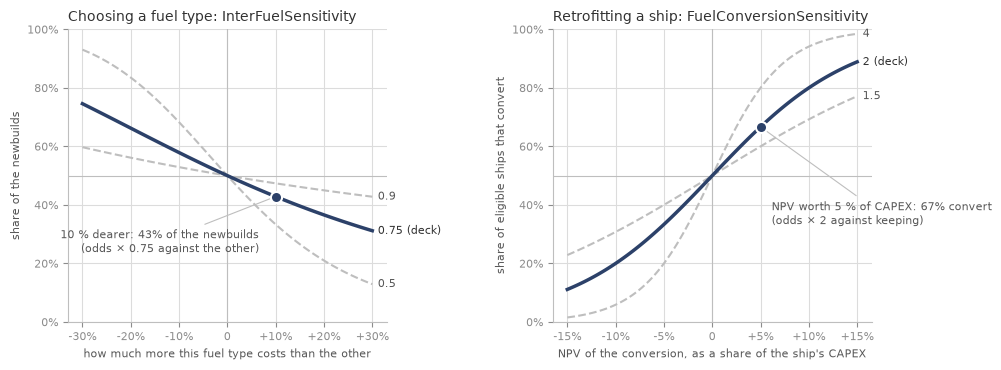

In [16]:
# @title Figure: how a sensitivity turns a cost gap into shares
# The two formulas above, drawn for a choice between two options only: the
# share one option gets as its gap to the other grows. With more options the
# odds ratios hold the same way, but the shares spread thinner.
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

_STYLE_DIR = str(Path("docs/workshop").resolve())
if _STYLE_DIR not in sys.path:
    sys.path.insert(0, _STYLE_DIR)
from _style import AXIS, BLUE, GRID, INK, MUTED, SUBINK, TICK

INTER_FUEL = scalar(fleet.inter_fuel_sensitivity)
FUEL_CONVERSION = scalar(fleet.fuel_conversion_sensitivity)


def share_by_cost(gap, odds):
    """Share of a fuel type whose cost is `gap` above (or below) the other's."""
    beta = -np.log(odds) / np.log(1.1)
    return 1 / (1 + (1 + gap) ** beta)


def share_by_npv(npv_over_capex, odds):
    """Share of eligible ships that convert, against keeping the ship."""
    beta = np.log(odds) / 0.05
    return 1 / (1 + np.exp(-beta * npv_over_capex))


def style(ax, title, xlab):
    ax.set_title(title, fontsize=10, color=INK, loc="left")
    ax.set_xlabel(xlab, fontsize=8, color=SUBINK)
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:+.0%}" if x else "0")
    ax.axhline(0.5, color=AXIS, lw=0.8, zorder=1)
    ax.axvline(0, color=AXIS, lw=0.8, zorder=1)
    ax.grid(color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TICK, labelsize=8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)


def curves(ax, x, share, deck, others, point):
    """The deck's value in bold, two others in grey, each labelled at its end."""
    for odds in others:
        ax.plot(x, share(x, odds), color=MUTED, lw=1.5, ls="--", zorder=2)
        ax.annotate(f"{odds:g}", (x[-1], share(x[-1], odds)), xytext=(4, 0),
                    textcoords="offset points", va="center", fontsize=8, color=SUBINK)
    ax.plot(x, share(x, deck), color=BLUE, lw=2.5, zorder=3)
    ax.annotate(f"{deck:g} (deck)", (x[-1], share(x[-1], deck)), xytext=(4, 0),
                textcoords="offset points", va="center", fontsize=8, color=INK)
    y = share(point, deck)
    ax.plot(point, y, "o", color=BLUE, ms=8, mec="white", mew=1.5, zorder=4)
    return y


fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))

gap = np.linspace(-0.3, 0.3, 121)
y = curves(left, gap, share_by_cost, INTER_FUEL, (0.9, 0.5), 0.10)
left.annotate(f"10 % dearer: {y:.0%} of the newbuilds\n(odds × {INTER_FUEL:g} against the other)",
              (0.10, y), xytext=(-12, -40), textcoords="offset points", ha="right",
              fontsize=8, color=SUBINK, arrowprops=dict(arrowstyle="-", color=AXIS, lw=0.8))
style(left, "Choosing a fuel type: InterFuelSensitivity",
      "how much more this fuel type costs than the other")
left.set_ylabel("share of the newbuilds", fontsize=8, color=SUBINK)

npv = np.linspace(-0.15, 0.15, 121)
y = curves(right, npv, share_by_npv, FUEL_CONVERSION, (1.5, 4), 0.05)
right.annotate(f"NPV worth 5 % of CAPEX: {y:.0%} convert\n(odds × {FUEL_CONVERSION:g} against keeping)",
               (0.05, y), xytext=(8, -70), textcoords="offset points", ha="left",
               fontsize=8, color=SUBINK, arrowprops=dict(arrowstyle="-", color=AXIS, lw=0.8))
style(right, "Retrofitting a ship: FuelConversionSensitivity",
      "NPV of the conversion, as a share of the ship's CAPEX")
right.set_ylabel("share of eligible ships that convert", fontsize=8, color=SUBINK)

fig.tight_layout(w_pad=4)
plt.show()


---

### 2. Data about the fuels

In this example, we assume that fossil fuels (fuel oil and LNG) have a flat price until 2050.

Electricity is more than 50% of what an e-fuel costs to make. It is assumed that its cost decreases in the future.

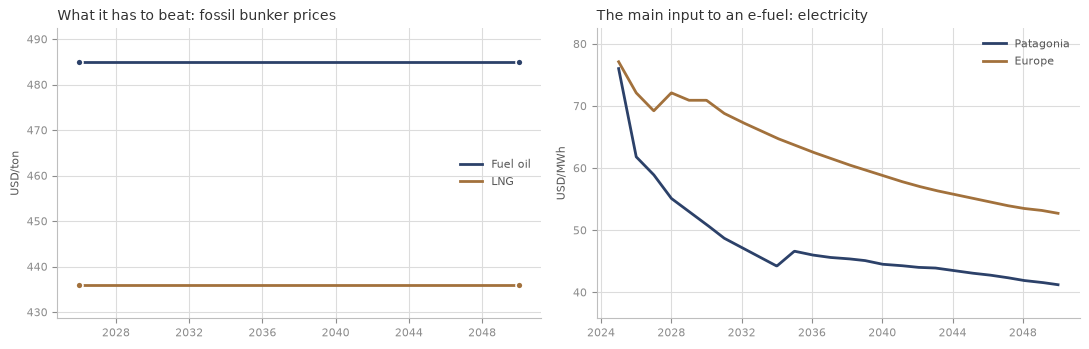

In [17]:
# @title Figure: fossil fuel and electricity prices
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))

panel(ax1, [("fossil_fuel_oil_price_global", "Fuel oil"),
            ("liquefied_natural_gas_price_global", "LNG")],
      "What it has to beat: fossil bunker prices", "USD/ton")
panel(ax2, [("electricity_cost_americas_mid", "Patagonia"),
            ("electricity_cost_europe_mid", "Europe")],
      "The main input to an e-fuel: electricity", "USD/MWh")

fig.tight_layout()
plt.show()


The synthesis and electrolyser cost tables are currently assumed flat in time. Learning rates (costs falling as more capacity is built) may be added in a future version of Navigate.

For bio-methanol, the CAPEX is a forecast that falls over time.

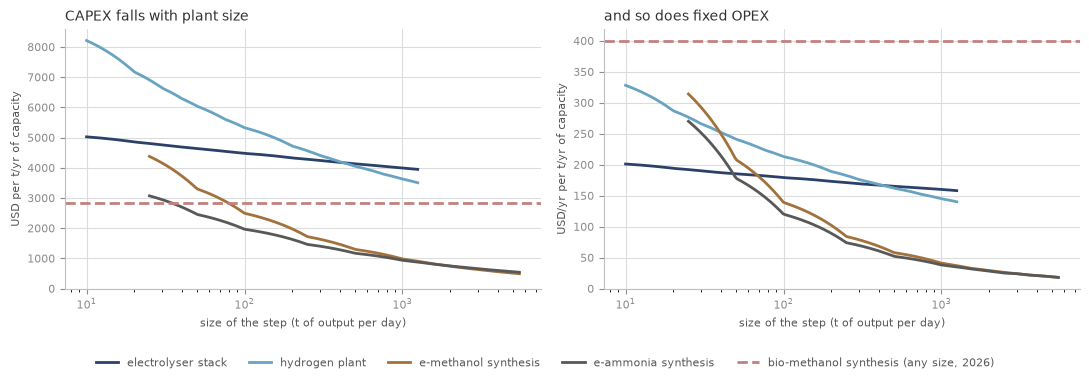

Additional input data


,inputs per t of output,electricity (MWh/t),life (yr)
step,,,
electrolyser stack,10.00 t demineralized_water,51.00,10.0
hydrogen plant,1.00 t electrolysis_stack_alkaline,4.00,20.0
e-methanol synthesis,"0.19 t hydrogen_electro_alkaline, 1.40 t carbo...",1.55,plant's
e-ammonia synthesis,"0.18 t hydrogen_electro_alkaline, 0.82 t nitro...",0.44,plant's
bio-methanol synthesis,2.42 t feedstock_biomethanol_gasification,0.52,plant's


Bio-methanol is costed per ton, not by size: CAPEX 2,840 USD per t/yr of capacity in 2026, fixed OPEX 400 USD/yr per t/yr.
Feedstock prices (USD/t): carbon_dioxide_biogenic 150, feedstock_biomethanol_gasification 65, demineralized_water 2


In [18]:
# @title Fuel production data, read off the deck
# Inputs only: every number here is read off the parsed deck, none from the run.
_region = manager.nodes.regions["europe"]     # the process economics are the same in every region
# the two hydrogen steps in blues
_STEPS = [("electrolysis_stack_alkaline", "electrolyser stack", BLUE),
          ("hydrogen_electro_alkaline", "hydrogen plant", series_colours(6)[5]),
          ("methanol_synthesis_electro_alkaline", "e-methanol synthesis", ORANGE),
          ("ammonia_synthesis_electro_alkaline", "e-ammonia synthesis", SUBINK)]


def size_curve(table):
    """A cost table across the plant sizes it is defined for, at the first year."""
    sizes = np.geomspace(table.get_y_min(), table.get_y_max(), 200)
    return sizes, np.array([table.get(0., s) for s in sizes])


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
for process, label, colour in _STEPS:
    for ax, table in ((ax1, _region.get_process_CAPEX(process)),
                      (ax2, _region.get_process_OPEX(process))):
        sizes, cost = size_curve(table)
        ax.plot(sizes, cost, color=colour, lw=2, label=label)
# bio-methanol is costed by year, not by size: a flat line at its 2026 value
_bio = "methanol_synthesis_bio_gasification"
for ax, cost in ((ax1, _region.get_process_CAPEX(_bio)), (ax2, _region.get_process_OPEX(_bio))):
    ax.axhline(scalar(cost, 0.), color=fuel_colour("methanol_bio"), lw=2, ls="--",
               label="bio-methanol synthesis (any size, 2026)")

for ax, title, ylab in ((ax1, "CAPEX falls with plant size", "USD per t/yr of capacity"),
                        (ax2, "and so does fixed OPEX", "USD/yr per t/yr of capacity")):
    ax.set_title(title, fontsize=10, color=INK, loc="left")
    ax.set_ylabel(ylab, fontsize=8, color=SUBINK)
    ax.grid(color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TICK, labelsize=8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)
for ax in (ax1, ax2):
    ax.set_xscale("log")
    ax.set_xlabel("size of the step (t of output per day)", fontsize=8, color=SUBINK)
    ax.set_ylim(0, None)
fig.legend(*ax1.get_legend_handles_labels(), loc="lower center", ncol=5,
           fontsize=8, frameon=False, labelcolor=SUBINK)
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

# What each step needs per ton of what it makes, at the first year.
print("Additional input data")
_rows = []
for process, label, _colour in _STEPS + [("methanol_synthesis_bio_gasification", "bio-methanol synthesis", None)]:
    node = manager.nodes.processes[process]
    feeds = ", ".join(f"{scalar(c):.2f} t {f.get_name()}" for f, c in zip(node.feeds, node.conversions))
    lifetime = _region.get_process_lifetime(process)
    _rows.append({"step": label,
                  "inputs per t of output": feeds,
                  "electricity (MWh/t)": scalar(_region.get_process_energy(process)),
                  "life (yr)": scalar(lifetime) if lifetime is not None else "plant's"})
display(pd.DataFrame(_rows).set_index("step"))

print("Bio-methanol is costed per ton, not by size: "
      f"CAPEX {scalar(_region.get_process_CAPEX(_bio), 0.):,.0f} USD per t/yr of capacity in 2026, "
      f"fixed OPEX {scalar(_region.get_process_OPEX(_bio)):,.0f} USD/yr per t/yr.")
print("Feedstock prices (USD/t): " + ", ".join(
    f"{f} {scalar(_region.get_feedstock_cost(f)):,.0f}"
    for f in ("carbon_dioxide_biogenic", "feedstock_biomethanol_gasification", "demineralized_water")))


#### Feedstock availability

The availability of fuels that contain carbon is limited by their carbon feedstock supply.
Bio-methanol needs gasifiable biomass, and e-methanol needs biogenic CO2.

Each cap is set in `includes/producer.inc`, on the producer that uses the feedstock,
and covers all of that producer's plants. The library gives the world's supply and
the share of it shipping could use; the deck keeps only a small share of that for
this example.

The cell below shows how much of each feedstock is available in this example.


  Gasification feedstock     ceiling  0.81 Mt/yr in 2026,  0.95 by 2050
  Biogenic CO2 (PS)          ceiling  0.14 Mt/yr in 2026,  0.14 by 2050


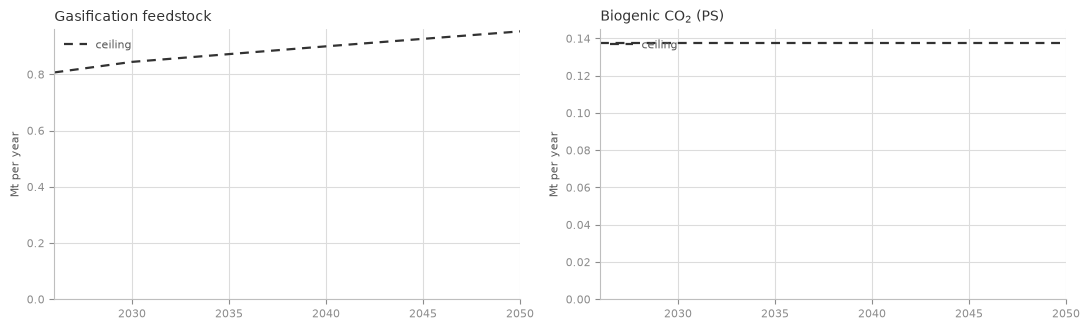

In [19]:
# @title Figure: feedstock ceilings
# What the two feedstock ceilings allow. The ceilings only - what the run draws
# against them is a result, and is plotted in Session 4.
#
# A ceiling is a deck EXPRESSION rather than a plain Forecast, so it is resolved
# the way this Part resolves emission factors: `calculate` where the node has
# one, `get(t)` where it does not.
from navigate.illustrations.plots._labels import FEEDSTOCK_LABEL

_days = manager.get_timeline()
_years = manager.get_dateline().astype("datetime64[Y]").astype(int) + 1970


def _feed_ceiling(node, when):
    """One feed ceiling in tons a year, `when` days from the start date."""
    if hasattr(node, "calculate"):
        return float(node.calculate(when))
    try:
        return float(node.get(when))
    except TypeError:
        return float(node.get())


# Every constrained feed in the deck, widest allowance first. That ordering is a
# property of the deck rather than of the run, so Session 4's figure computes it the
# same way and the two read in the same order.
CEILINGS = sorted(
    ({"feed": _feed,
      "cap": np.array([_feed_ceiling(_node, _w) for _w in _days]) / 1e6}
     for _producer in manager.nodes.producers.values()
     for _feed, _node in _producer.feed_constraints.items() if _node is not None),
    key=lambda c: -c["cap"][-1])

fig, axes = plt.subplots(1, len(CEILINGS), figsize=(11, 3.4), sharex=True)

for ax, c in zip(np.atleast_1d(axes), CEILINGS):
    ax.plot(_years, c["cap"], color=INK, lw=1.6, ls=(0, (4, 3)), label="ceiling")
    ax.set_title(FEEDSTOCK_LABEL.get(c["feed"], c["feed"]), fontsize=10,
                 color=INK, loc="left")
    ax.set_ylabel("Mt per year", fontsize=8, color=SUBINK)
    ax.set_ylim(bottom=0.)
    ax.margins(x=0)
    ax.legend(fontsize=8, frameon=False, labelcolor=SUBINK, loc="upper left")
    ax.grid(color=GRID, lw=.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TICK, labelsize=8)
    for _side in ("top", "right"):
        ax.spines[_side].set_visible(False)
    for _side in ("left", "bottom"):
        ax.spines[_side].set_color(AXIS)

fig.tight_layout()

for c in CEILINGS:
    # the display labels carry mathtext for the figure, so flatten it for print
    _name = FEEDSTOCK_LABEL.get(c["feed"], c["feed"]).replace("$_2$", "2").replace("$", "")
    print(f"  {_name:26} ceiling {c['cap'][0]:5.2f} Mt/yr in {_years[0]}, "
          f"{c['cap'][-1]:5.2f} by {_years[-1]}")
plt.show()

---

### 3. Data about bunkering

This deck adds a transport cost, `distance × rate` from the plant to the bunker port,
to the cost of each fuel. It means that fuel is cheap at the port next door and carries a
penalty at the far one. The values are invented for this example.


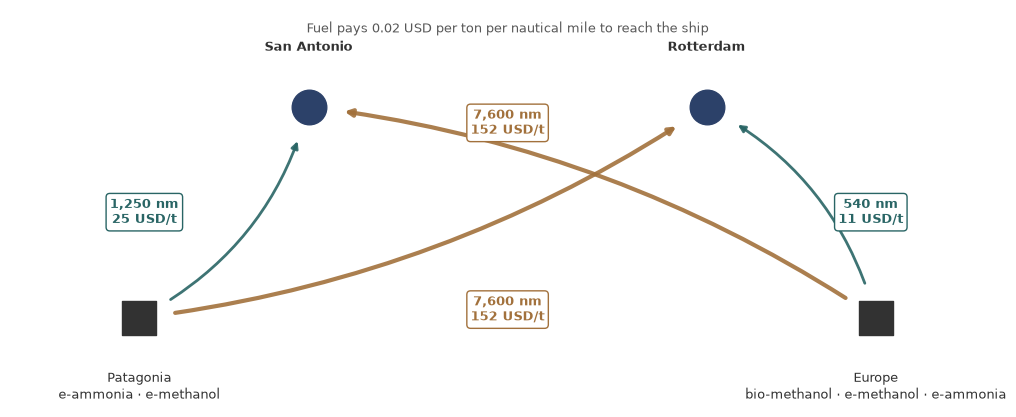

In [20]:
# @title Figure: bunker logistics
import re

text = (EXAMPLE / "includes" / "bunker_logistics.inc").read_text(encoding="utf-8")

# USD per ton per nautical mile (Navigate: `set_transport_cost`)
USD_PER_TON_NM = float(
    re.search(r'set_transport_cost\("\*",\s*([\d.]+)\)', text).group(1))

# One entry per journey the FUEL makes, plant region -> bunker port
# (Navigate: `set_distance`, from a Region to a Port). Navigate keeps the word
# "leg" (a ship's sailing from one port to the next) for the ship's own route
# segments, so these are trips, not legs.
FUEL_DELIVERY_TRIPS = [(region, port, int(nm)) for region, port, nm in
                       re.findall(r'set_distance\("(\w+)",\s*"(\w+)",\s*(\d+)\)', text)]

# Drawn rather than tabulated: the point is the CONTRAST between fuel bunkered
# next door and fuel shipped to the far port, which a table makes you work out.
# Positions are schematic - this is the supply chain, not a projection.
POS = {"americas": (0.13, 0.24), "san_antonio": (0.30, 0.76),
       "europe": (0.87, 0.24), "rotterdam": (0.70, 0.76)}
CAPTION = {"americas": "Patagonia\ne-ammonia · e-methanol",
           "europe": "Europe\nbio-methanol · e-methanol · e-ammonia",
           "san_antonio": "San Antonio", "rotterdam": "Rotterdam"}
LOCAL = {("americas", "san_antonio"), ("europe", "rotterdam")}
# arc curvature, then where the label sits; keeps the two crossings legible
DRAW = {("americas", "san_antonio"): (0.22, 0.135, 0.50),
        ("europe", "rotterdam"): (0.22, 0.865, 0.50),
        ("americas", "rotterdam"): (0.12, 0.50, 0.26),
        ("europe", "san_antonio"): (0.12, 0.50, 0.72)}

fig, ax = plt.subplots(figsize=(10.5, 4.3))

for region, port, nm in FUEL_DELIVERY_TRIPS:
    rad, lx, ly = DRAW.get((region, port), (0.12, 0.5, 0.5))
    local = (region, port) in LOCAL
    colour = GREEN if local else ORANGE
    ax.annotate("", xy=POS[port], xytext=POS[region],
                arrowprops=dict(arrowstyle="-|>", color=colour,
                                lw=2.0 if local else 3.0, alpha=0.9,
                                connectionstyle=f"arc3,rad={rad}",
                                shrinkA=26, shrinkB=26))
    ax.text(lx, ly, f"{nm:,} nm\n{nm * USD_PER_TON_NM:.0f} USD/t",
            ha="center", va="center", fontsize=9, color=colour,
            fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.30", fc="white", ec=colour, lw=1.0))

for name, (x, y) in POS.items():
    is_port = name in ("san_antonio", "rotterdam")
    ax.scatter([x], [y], s=620, marker="o" if is_port else "s",
               color=BLUE if is_port else INK, zorder=4)
    ax.text(x, y + (0.13 if is_port else -0.13), CAPTION[name], ha="center",
            va="bottom" if is_port else "top", fontsize=9.5, color=INK,
            fontweight="bold" if is_port else "normal")

ax.text(0.5, 0.97, f"Fuel pays {USD_PER_TON_NM} USD per ton per nautical mile "
                   f"to reach the ship", ha="center", va="top", fontsize=9,
        color=SUBINK)
ax.set_xlim(0, 1)
ax.set_ylim(0.02, 1.0)
ax.axis("off")
fig.tight_layout()
plt.show()


---

### 4. Data about the regulations

The modelled regulations are driven by five factors: the **allowance price**,
the **intensity target**, the **penalty** for missing that target, the **scope** of emissions, and **how
much of the voyage is counted** at all. The first two are Forecasts and are
plotted below; the third is a single `Variable`; the fourth is described just below;
the fifth was set back in Part 1, as `Jurisdiction` and the three coverage fractions.

The EU ETS is `Scope = TTW`, so it zero-rates the combustion carbon of every alternative
fuel — e-ammonia, e-methanol and bio-methanol carry the same factors per ton,
leaving only their methane and nitrous oxide to charge. FuelEU is
`Scope = WTW`, so it can influence the choices between the different
alternative fuel supplies.


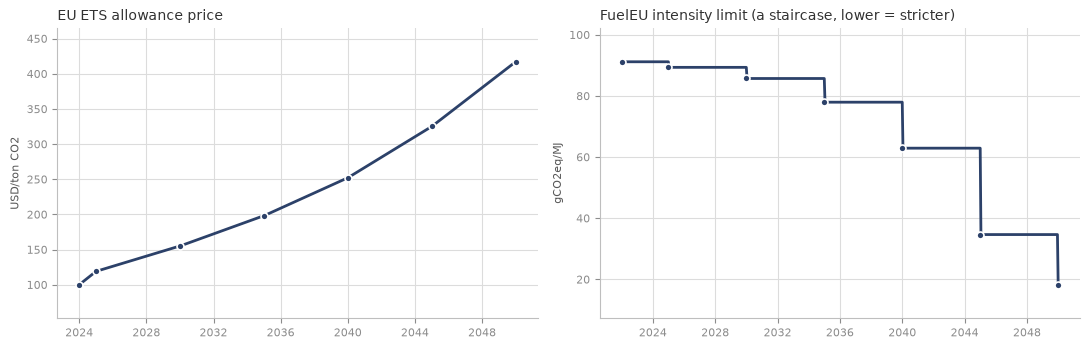

ETS allowance (USD/ton CO2)          100.0 (2024)  ->    417.0 (2050)
FuelEU limit (gCO2eq/MJ)              91.2 (2022)  ->     18.2 (2050)

FuelEU penalty for missing the cap   760.0 USD/ton, flat
EU ETS phase-in at the 2026 start     100% of emissions priced


In [21]:
# @title Figure: regulation prices and targets
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))

panel(ax1, [("eu_ets_carbon_credit_price", None)],
      "EU ETS allowance price", "USD/ton CO2")
panel(ax2, [("fuel_eu_target_reduction", None)],
      "FuelEU intensity limit (a staircase, lower = stricter)", "gCO2eq/MJ")

fig.tight_layout()
plt.show()

for name, label in [("eu_ets_carbon_credit_price", "ETS allowance (USD/ton CO2)"),
                    ("fuel_eu_target_reduction", "FuelEU limit (gCO2eq/MJ)")]:
    df = forecast_to_frame(name)
    first, last = df.iloc[0], df.iloc[-1]
    print(f"{label:34} {first['value']:7.1f} ({first['date'].year})"
          f"  ->  {last['value']:7.1f} ({last['date'].year})")

# The lever that actually moves the answer is not a Forecast at all: a single
# number with no axis is a `Variable`, read with .get().
penalty = manager.nodes.variables["fuel_eu_remedial_cost"].get()
print(f"\n{'FuelEU penalty for missing the cap':34} {penalty:7.1f} USD/ton, flat")

# And the ETS is not phasing in over this run: it is complete on day one.
phase_in = forecast_to_frame("eu_ets_maritime_phase_in")
started = phase_in.loc[phase_in["date"].dt.year <= 2026, "value"].iloc[-1]
print(f"{'EU ETS phase-in at the 2026 start':34} {started:7.0%} of emissions priced")


The ETS price climbs steadily and the FuelEU limit hardly moves before 2035,
then falls away in steps. So the pressure arrives early as a price and late as
a cap. Breaching the cap leads to a **760 USD/ton penalty**, which is the strongest single lever in the deck.

#### What each regulation actually counts

The `Scope` (WTW or TTW) decides which part of the fuel chain is counted by each regulation. The graph below shows what is counted for each regulation.

The two e-fuels have no WTT written in `fuel_eu.inc` on purpose: Navigate derives theirs from the production chain the deck defines since they have no regulatory default values.

The same fuel can also score a different **TTW** for FuelEU and EU ETS because each regulation carries its own emission factors.

**FuelEU is WTW**, so it charges the full combustion carbon of the molecule at the funnel. Bio-methanol is charged 72 gCO2eq/MJ TTW (the same as e-methanol, because burning either releases the same carbon). In the case of biogenic carbon use, the WTT component is credited with a negative value. That is not a modelling shortcut: the regulation derives the WTT from the lifecycle value on the fuel's Proof of Sustainability, reduced by the combustion carbon.

**The EU ETS is TTW**. It zero-rates the combustion CO2 of bio- and e-fuels. So for bio-methanol the TTW is about 2 (for N2O and CH4 emissions).

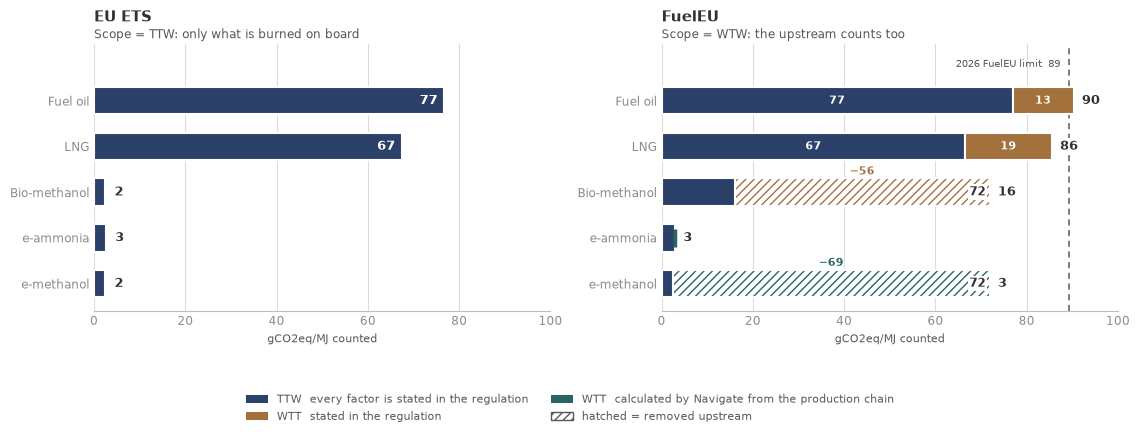

In [22]:
# @title Table: what each regulation charges each fuel
# What each regulation charges each fuel, and where each number comes from.
# The factors come from DECK_FACTORS, the copy Part 2's data-extraction cell took
# of the Regulation nodes before solving (`set_fuel_ttw` / `set_fuel_wtt` in eu_ets.inc and fuel_eu.inc).
# Where a regulation states no WTT of its own, Navigate derives one from the
# production chain instead, which is what the solved run supplies.
from navigate.illustrations.plots._labels import FUEL_LABEL, FUEL_ORDER

# Navigate's own display names and canonical fuel order, so this figure reads the
# same way as the plots the model generates. FUEL_ORDER covers every fuel the
# library knows about, so keep the five this deck actually defines.
ORDER = [f for f in FUEL_ORDER if f in manager.nodes.fuels]


def factor(node, t=0.):
    """An emission-factor node resolved to a number, or None where the deck leaves it open."""
    if node is None:
        return None
    if hasattr(node, "calculate"):
        return float(node.calculate(t))
    try:
        return float(node.get(t))      # expressions carry a Forecast, so they need a date
    except TypeError:
        return float(node.get())


def modelled_wtt(fuel_name, emission, idx=0):
    """The upstream emissions Navigate derives for a fuel from its production chain.

    The plant's own production emissions plus the delivery trip to the bunker port.
    Readable only because Part 2's data-extraction cell solved the deck -- none of this is written
    down in a .inc file. A fuel with no plant (the two fossils) has no chain, so
    there is nothing to derive.
    """
    for plant in manager.nodes.plants.values():
        if plant.fuel.get_name() != fuel_name:
            continue
        production = plant.expectation.get_production_WTT(emission, idx)
        delivery = max(plant.expectation.get_delivery_WTT(port, emission, idx)
                       for port in manager.nodes.ports)
        return production + delivery
    return None


def counted_intensity(regulation, fuel_name):
    """What `regulation` charges `fuel_name` as gCO2eq/MJ, and where the WTT came from.

    Returns (TTW, WTT, source). ton emission/ton fuel x GWP / (GJ/ton) x 1e3 -> g/MJ,
    using the regulation's OWN global warming potentials -- the two instruments do not
    use the same ones. `source` is "regulation" where the deck states a WTT factor and
    "navigate" where it states none and the production chain supplies it instead.
    """
    lhv = factor(manager.nodes.fuels[fuel_name].lower_heating_value)
    counts_wtt = str(regulation.scope).endswith("WTW")
    deck = DECK_FACTORS[regulation.get_name()]
    ttw, wtt, source = 0., 0., "regulation"
    for emission, gwp_node in deck["gwp"].items():
        gwp = factor(gwp_node)
        ttw_factor = factor(deck["ttw"].get((fuel_name, emission)))
        wtt_factor = factor(deck["wtt"].get((fuel_name, emission)))
        if wtt_factor is None and counts_wtt:
            wtt_factor, source = modelled_wtt(fuel_name, emission), "navigate"
        ttw += 0. if ttw_factor is None else ttw_factor * gwp / lhv * 1e3
        wtt += 0. if wtt_factor is None else wtt_factor * gwp / lhv * 1e3
    return ttw, wtt, source


from matplotlib.patches import Patch

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), sharex=True)
PANELS = [("eu_ets", "EU ETS", "Scope = TTW: only what is burned on board"),
          ("fuel_eu", "FuelEU", "Scope = WTW: the upstream counts too")]
LABEL_BOX = dict(boxstyle="square,pad=0.15", fc="white", ec="none")
LABEL_MIN = 10          # a bar narrower than this cannot hold a number

for ax, (reg_name, title, subtitle) in zip(axes, PANELS):
    reg = manager.nodes.regulations[reg_name]
    counts_wtt = str(reg.scope).endswith("WTW")

    for i, fuel in enumerate(ORDER):
        ttw, wtt, source = counted_intensity(reg, fuel)
        net = ttw + wtt if counts_wtt else ttw
        colour = ORANGE if source == "regulation" else GREEN

        ax.barh(i, ttw, height=.6, color=BLUE, zorder=3,
                edgecolor="white", linewidth=1.5)
        if counts_wtt and wtt > 0:
            ax.barh(i, wtt, left=ttw, height=.6, color=colour, zorder=3,
                    edgecolor="white", linewidth=1.5)
        elif counts_wtt and wtt < 0:
            # the regulation really does remove these emissions upstream, so the credit
            # is drawn eating into the TTW bar rather than extending it: what is left
            # solid is what actually counts
            # the hatch is drawn in the edge colour, so it goes on with no outline;
            # the white outline is added separately, matching the solid bars exactly,
            # so both end up the same visible thickness
            ax.barh(i, ttw - net, left=net, height=.6, facecolor="white", zorder=4,
                    edgecolor=colour, linewidth=0, hatch="////")
            ax.barh(i, ttw - net, left=net, height=.6, facecolor="none", zorder=4,
                    edgecolor="white", linewidth=1.5)
        elif counts_wtt:
            # a derived WTT that comes out at zero still has a provenance worth showing
            ax.plot([ttw], [i], marker="|", ms=13, mew=2.5, color=colour, zorder=5)

        # A single-part row (the EU ETS panel) carries one number: inside the bar,
        # or just outside it when the bar is too narrow to hold it.
        if not counts_wtt:
            if ttw >= LABEL_MIN:
                ax.annotate(f"{ttw:.0f}", (ttw - 1.5, i), ha="right", va="center",
                            fontsize=9, color="white", fontweight="bold", zorder=6)
            else:
                ax.annotate(f"{ttw:.0f}", (ttw + 2, i), va="center", fontsize=9,
                            color=INK, fontweight="bold", zorder=6)
        else:
            # Read the same way as the fuel-and-compliance bills: every part that
            # shows at the printed precision carries its number, a removed part
            # with its minus sign on top of its hatching, and the total after the
            # bar is the sum of what is printed, so the row adds up as printed.
            shown_ttw, shown_wtt = round(ttw), round(wtt)
            if shown_wtt < 0:
                # the TTW number sits at the end of the TTW extent, which on a
                # credited row is the far edge of the hatching
                ax.annotate(f"{shown_ttw}", (ttw, i), xytext=(-3, 0),
                            textcoords="offset points", ha="right", va="center",
                            fontsize=8.5, fontweight="bold", zorder=6, color=INK,
                            bbox=LABEL_BOX)
                ax.annotate(f"\u2212{-shown_wtt}", ((net + ttw) / 2, i - .3),
                            xytext=(0, 1), textcoords="offset points", ha="center",
                            va="bottom", fontsize=8, color=colour,
                            fontweight="bold", zorder=6)
            elif shown_wtt > 0:
                for value, start in ((ttw, 0.), (wtt, ttw)):
                    if value >= LABEL_MIN:
                        ax.annotate(f"{round(value)}", (start + value / 2, i),
                                    ha="center", va="center", fontsize=8,
                                    color="white", fontweight="bold", zorder=6)
                    else:
                        # too narrow to hold its number: just above the bar
                        ax.annotate(f"{round(value)}", (start + value / 2, i - .3),
                                    xytext=(0, 1), textcoords="offset points",
                                    ha="center", va="bottom", fontsize=7.5,
                                    color=INK, zorder=6)
            # with a single part, the total is its number
            ax.annotate(f"{shown_ttw + shown_wtt}", (max(ttw, net), i), xytext=(6, 0),
                        textcoords="offset points", va="center", fontsize=9,
                        color=INK, fontweight="bold", zorder=6, bbox=LABEL_BOX)

    if counts_wtt:
        limit = factor(manager.nodes.forecasts["fuel_eu_target_reduction"])
        ax.axvline(limit, color=SUBINK, lw=1.1, ls=(0, (4, 3)), zorder=2)
        ax.annotate(f"2026 FuelEU limit  {limit:.0f}", (limit - 2, -.8),
                    fontsize=7.5, color=SUBINK, ha="right", va="center")

    ax.set_title(title, fontsize=11, color=INK, loc="left", pad=16, fontweight="bold")
    ax.annotate(subtitle, (0, 1.02), xycoords="axes fraction", fontsize=8.5, color=SUBINK)
    ax.set_xlabel("gCO2eq/MJ counted", fontsize=8, color=SUBINK)
    ax.set_xlim(0, 100)
    ax.set_ylim(len(ORDER) - .4, -1.25)
    ax.set_yticks(range(len(ORDER)), [FUEL_LABEL[f] for f in ORDER])
    ax.grid(axis="x", color=GRID, lw=.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TICK, labelsize=8.5, length=0)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)

fig.legend(handles=[Patch(facecolor=BLUE, label="TTW  every factor is stated in the regulation"),
                    Patch(facecolor=ORANGE, label="WTT  stated in the regulation"),
                    Patch(facecolor=GREEN, label="WTT  calculated by Navigate from the production chain"),
                    Patch(facecolor="white", edgecolor=SUBINK, hatch="////",
                          label="hatched = removed upstream")],
           fontsize=8, frameon=False, labelcolor=SUBINK, ncol=2,
           loc="lower center", bbox_to_anchor=(.5, .005))
fig.tight_layout(rect=(0, .17, 1, 1))
plt.show()


When reading across the two panels you can see that, for bio-methanol, EU ETS gives 2 gCO2eq/MJ of TTW emissions and FuelEU 16 gCO2eq/MJ. The gap between those totals is bio-methanol's own production footprint: about 14 gCO2eq/MJ of growing, gasifying and shipping the biomass. FuelEU counts it; the ETS never looks upstream, so it cannot see it. The ETS therefore scores bio-methanol some 97 % better than fuel oil where FuelEU says 82 %.

## Workshop sessions

**Next: [Session 4: How Navigate solves](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/workshop/04-how-navigate-solves.ipynb)**

Each link opens the notebook in Google Colab, in a fresh session, so run it
from the top.

1. [Run a simple case](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/workshop/01-run-a-simple-case.ipynb)
2. [Run a global case](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/workshop/02-run-a-global-case.ipynb)
3. **How a Navigate model is built** (this session)
4. [How Navigate solves](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/workshop/04-how-navigate-solves.ipynb)
5. [Build your own case](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/workshop/05-build-your-own-case.ipynb)